### 이진 분류 
: Banknote Authentication 데이터셋 : 진짜 지폐와 가짜 지폐를 판별<br>

- 데이터 : 1372개<br>
- 정답 : 0 -> 진짜, 1 -> 가짜<br>
- 입력특징 : 4게<br>
    variance(분산)<br>
    skewness(왜도) : 좌우 어느 방향으로 치우쳐져 있는지<br>
    curtosis(첨도) : 분포의 뾰족한 정도<br>
    entropy(엔트로피) : 낮으면 특정값이나 패턴에 집중되어 있는 뜻, <br>
    높으면 다양한 값이 나타나고 분포가 복잡해지는 경향<br>

- 4개의 특징값(입력값)으로 사용하고, 결과(진짜지폐, 가짜지폐) 예측

In [29]:
import pandas as pd
import torch 
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt 
import numpy as np 
import random 

#### Step 1. 데이터 불러오기 및 전처리 

In [ ]:
# 구버전 사이트
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt'

columns = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
df = pd.read_csv('data_banknote_authentication.txt', names = columns)

print(df.head())
print('데이터의 크기 :', df.shape)
print('클래스별 데이터 개수 : ')
print(df['class'].value_counts().sort_index())

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
데이터의 크기 : (1372, 5)
클래스별 데이터 개수 : 
class
0    762
1    610
Name: count, dtype: int64


In [ ]:
# 입력데이터(x)와 정답데이터(y) 분리 
X = torch.tensor(df[['variance', 'skewness', 'curtosis', 'entropy']].values, 
                    dtype=torch.float32) # (1372,4) 행렬 
y = torch.tensor(df['class'].values, dtype = torch.float32).reshape(-1,1)

# 클래스별로 학습/테스트 데이터를 나눔
torch.manual_seed(42) # 시드개수 42개는 딱히 근거없음.. 
train_indices = []
test_indices = []

for class_value in [0, 1] : 
    class_indices = [] 

    for i in range(len(y)) : 
        if y[i].item() == class_value : 
            class_indices.append(i)

    # 순서를 무작위로 섞기 
    random.shuffle(class_indices)

    # 학습 80%, 테스트 20% 분리 
    split = int(len(class_indices) * 0.8)

    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])


for class_value in [0,1] : 
    # where() : 조건을 만족하는 데이터 찾기. 결과 튜플 반환
    class_indices = torch.where(y.squeeze() == class_value)[0]
    # randperm() : 0부터 지정한 숫자까지의 정수를 무작위로 섞어서 반환 
    class_indices = class_indices[torch.randperm(len(class_indices))]

    # 학습 80%, 테스트 20% 분리 
    split = int(len(class_indices) * 0.8)

    train_indices.extend(class_indices[:split]) # extend 리스트에 다른 리스트 요소를 추가하는 메서드
    test_indices.extend(class_indices[split:])

print(len(train_indices))
print(len(test_indices))

# 학습 / 테스트 데이터 섞기 (클래스 0 앞쪽에, 클래스 1 뒤쪽에 몰려있는거 섞기)
train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

X_train = X[train_indices]   # X_train = (1092, 4)
X_test = X[test_indices]     # X_test = (275,4)
y_train = y[train_indices]   # y_train = (1092,1)
y_test = y[test_indices]     # y_test = (275,1)

# 데이터 정규화. 데이터끼리 편차가 클 때 평균 0, 표준편차가 1로 정규화 후 학습 
mean = X_train.mean(dim=0)  # 행의 방향 즉 열의 평균 
std = X_train.std(dim=0).clamp(min = 1e-8) # clamp(대체값) 최댓값과 최솟값의 범위를 제한해줌 std가 0이면 안됨. 

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print('X_train : ', X_train.shape)
print('y_train : ', y_train.shape)
print('X_test : ', X_test.shape)
print('y_test : ', y_test.shape)

550
550
X_train :  torch.Size([2194, 4])
y_train :  torch.Size([2194, 1])
X_test :  torch.Size([550, 4])
y_test :  torch.Size([550, 1])


In [32]:
# DataLoader 생성
BATCH_SIZE = 32

train_DS = TensorDataset(X_train, y_train)
test_DS = TensorDataset(X_test,y_test)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)

N = len(train_DL.dataset)
print(N)

2194


### Step 2. 모델 만들기 

In [33]:
class MLP(nn.Module) :
    def __init__(self) : 
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )
    def forward(self, x) : 
        x = self.linear(x)
        return x 

model = MLP()    

#### Step 3. 모델 학습 시키기 

In [34]:
LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history = []

model.train()
for ep in range(EPOCH) : 
    rloss = 0

    for x_batch, y_batch in train_DL : 
        # inference
        y_hat = model(x_batch)

        # loss
        loss = criterion(y_hat, y_batch)

        # update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss / N 
    loss_history.append(epoch_loss)

    print(f'Epoch : {ep+1}, train Loss : {epoch_loss : .4f}')
    print('-'*20)

Epoch : 1, train Loss :  0.5230
--------------------
Epoch : 2, train Loss :  0.3328
--------------------
Epoch : 3, train Loss :  0.2433
--------------------
Epoch : 4, train Loss :  0.1887
--------------------
Epoch : 5, train Loss :  0.1528
--------------------
Epoch : 6, train Loss :  0.1288
--------------------
Epoch : 7, train Loss :  0.1113
--------------------
Epoch : 8, train Loss :  0.0985
--------------------
Epoch : 9, train Loss :  0.0891
--------------------
Epoch : 10, train Loss :  0.0813
--------------------
Epoch : 11, train Loss :  0.0753
--------------------
Epoch : 12, train Loss :  0.0707
--------------------
Epoch : 13, train Loss :  0.0661
--------------------
Epoch : 14, train Loss :  0.0631
--------------------
Epoch : 15, train Loss :  0.0602
--------------------
Epoch : 16, train Loss :  0.0578
--------------------
Epoch : 17, train Loss :  0.0557
--------------------
Epoch : 18, train Loss :  0.0533
--------------------
Epoch : 19, train Loss :  0.0521
----

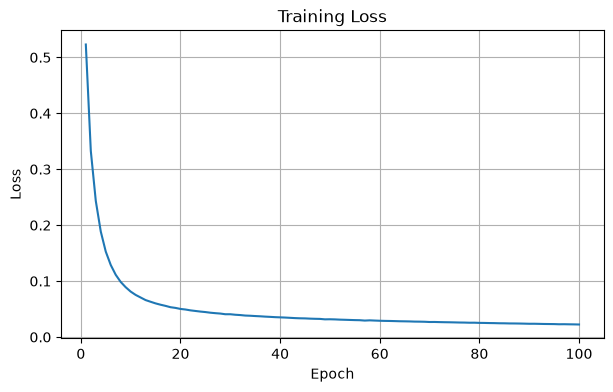

In [35]:
plt.figure(figsize = (7,4))
plt.plot(range(1, EPOCH + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.grid()

### Step 4. 모델 테스트 하기

In [36]:
model.eval()

correct = 0
total = 0
with torch.no_grad() : 
    for x_batch, y_batch in test_DL : 
        y_hat = model(x_batch)
        pred = (y_hat >= 0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct / total * 100
print(f'Test accuracy : {correct}/{total} ({accuracy:.1f}%)')

Test accuracy : 542/550 (98.5%)


### Step 5. 테스트 결과 시각화 

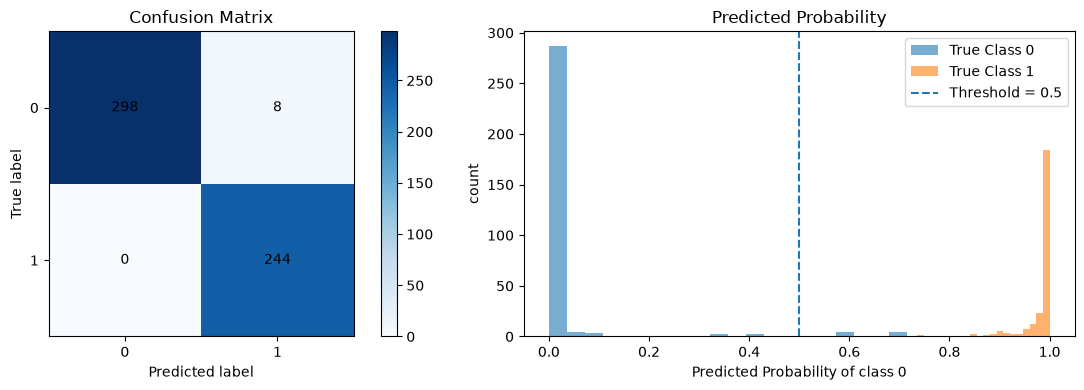

In [44]:
model.eval()

y_true_all = [] # 정답 전체
y_prob_all = [] # 예측 전체 

with torch.no_grad() :
    for x_batch, y_batch in test_DL : 
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))
        y_prob_all.append(y_hat.numpy().reshape(-1))

# 배치별로 나누어 저장했던 실제 정답 배열들을 하나로 합친다음, 데이터 타입 정수형으로 변환 
y_true = np.concatenate(y_true_all).astype(int)
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >= 0.5). astype(int)

# 혼동행렬 : 행은 실제 클래스, 열은 예측 클래스 
cm = np.zeros((2,2), dtype = int)
for true, pred in zip(y_true, y_pred) : ## zip : 같은 요소끼리 묶어주는 것 
    cm[true, pred] += 1

fig, axes = plt.subplots(1, 2, figsize=(12,4))

im = axes[0].imshow(cm, cmap = 'Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels = ['0','1'])
axes[0].set_yticks([0,1], labels = ['0','1'])

for i in range(2) : 
    for j in range(2) : 
        axes[0].text(j, i, cm[i,j], ha = 'center', va = 'center')

fig.colorbar(im, ax = axes[0])

# 클래스별 예측 확률 분포 
axes[1].hist(y_prob[y_true == 0], bins = 20, alpha = 0.6, label = 'True Class 0')
axes[1].hist(y_prob[y_true == 1], bins = 20, alpha = 0.6, label = 'True Class 1')
axes[1].axvline(0.5, linestyle = '--', label='Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()
plt.tight_layout()

plt.show()

